# Analysis AI-Team

### Load and import 

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch

# Plotly: also save a PNG copy of every figure, so it shows on GitHub (needs kaleido + Chrome)
import plotly.io as pio
try:
    go.Figure().to_image(format="png")
    pio.renderers.default = "plotly_mimetype+png"
except Exception as e:
    print(f"Plotly PNG copies off ({type(e).__name__}): figures will not show on GitHub")

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------------------
import importlib
import importlib, pair_a.q1_errorstructure as q1
from pair_a import q3_visualcues as q3


print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()
    
# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

Plotly PNG copies off (BrowserFailedError): figures will not show on GitHub
PyTorch 2.11.0+cu128 | CUDA build 12.8


/home/mut/projects/AI4VIS/ai_and_visualisation_OpenSI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 4070 Ti SUPER
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}, {subregion}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


# Q1: Error structure and geography 
Which countries are confused, what do confused pairs share, are there attractor countries, do errors cluster geographically?

In [2]:
importlib.reload(q1)

preds_df = preds.loc[preds["representable"]].copy()
country_meta_df = mapper.table.reset_index().copy()

q1_cfg = q1.Q1Config(
    true_col="country_id",
    pred_col="pred_1",
    topk_cols=["pred_1", "pred_2", "pred_3", "pred_4", "pred_5"],

    image_id_col="id",
    lat_col="latitude",
    lon_col="longitude",

    meta_country_col="iso2",
    meta_code_col="iso2",
    continent_col="continent",
    subregion_col="world_subregion",
    neighbors_col="neighbors",

    meta_lat_col="center_lat",
    meta_lon_col="center_lng",

    scalar_attrs=("driving_side", "landlocked"),
    list_attrs=("languages",),
    list_sep=";",

    min_n=20,
    n_permutations=1000,
    seed=42,
)

data = q1.Q1DataBuilder(preds_df, country_meta_df, q1_cfg).build()
ana = q1.Q1Analyser(data)
rep = q1.Q1Reporter(ana)

rep.summary()

Q1 data summary
  images used:          208,314 (input rows 208,314)
  countries in test:    188 (175 with n >= 20)
  top-k available:      [1, 3, 5]
  overall error top-1:  0.509
  overall error top-3:  0.299
  overall error top-5:  0.220


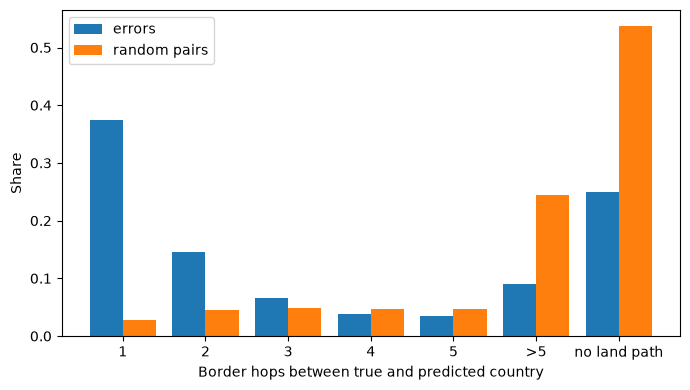

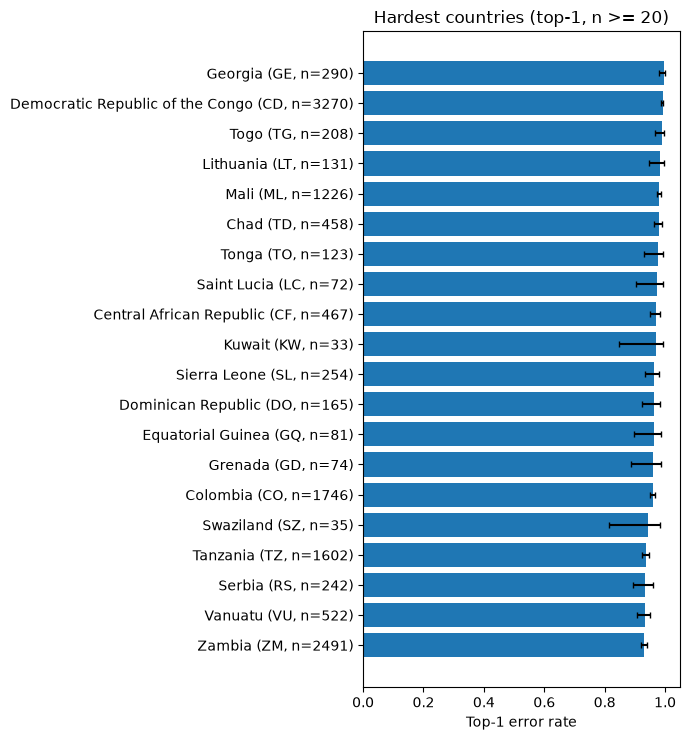

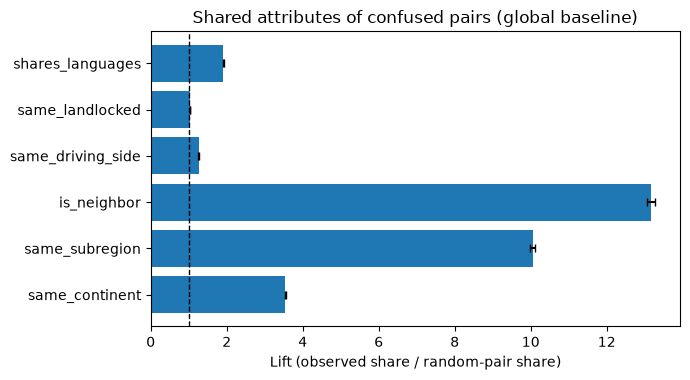

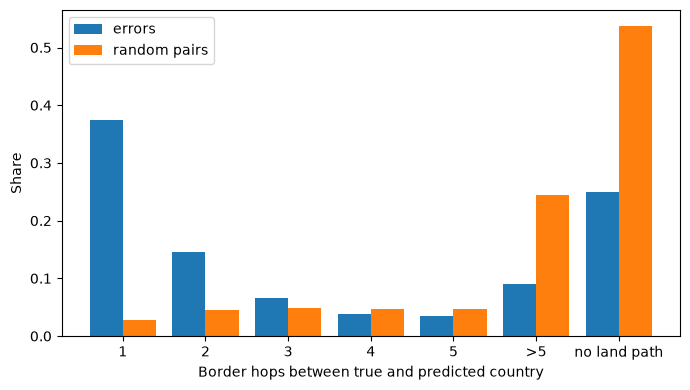

In [3]:
glob = ana.feature_baseline()   # shared attributes of confused pairs vs. random pairs
rep.plot_difficulty(); rep.plot_feature_lift(glob); rep.plot_hop_distribution()

In [4]:
importlib.reload(q1)

dash_q1 = q1.Q1Dashboard(ana)   # computes all baselines once (takes a bit with 1000 permutations)
dash_q1.run()                   # opens inline under this cell

# dash_q1.run(mode="tab")       # same app in a new browser tab
# dash_q1.run(port=8051)        # if it says the port is already in use after a re-run

- Tables behind the Q1 findings (the dashboard above does not show on GitHub)

In [5]:
from pair_a import viz
names = mapper.table["prompt_name"]
named = lambda c: f"{names.get(c, c)} ({c})"

# 1) Hardest and easiest countries: how many top-1 errors are back in the top 5?
tk = ana.topk_comparison().set_index("country").loc[["GE", "CD", "LT", "IS", "GL"]]
tk.index = tk.index.map(named)
display(viz.show_table(tk, {"n": "Images", "error_rate_top1": "Error top-1", "error_rate_top5": "Error top-5",
                            "recovered_in_top5": "Top-1 errors back in top 5"},
                       pct=["error_rate_top1", "error_rate_top5", "recovered_in_top5"]))

# 2) Largest confusion pairs A -> B and the reverse direction B -> A
pairs = ana.top_confusion_pairs(n=12)
pairs.index = [f"{names.get(a, a)} -> {names.get(b, b)}" for a, b in zip(pairs.true_country, pairs.pred_country)]
pairs["neighbour"] = pairs["is_neighbor"].map({1.0: "yes", 0.0: "no"})
display(viz.show_table(pairs, {"count": "Errors A -> B", "p_pred_given_true_error": "Share of A's errors",
                               "reverse_count": "Errors B -> A", "neighbour": "Land neighbours"},
                       pct=["p_pred_given_true_error"]))

# 3) Attractors: countries guessed much more often than they occur
att = ana.attractors().head(6)
att["country"] = att["country"].map(named)
att["ratio"] = att["prediction_ratio"].map(lambda r: f"{r:.1f}x")
att["source"] = att["fp_top_source"].map(names)
display(viz.show_table(att, {"country": "Country", "n": "Images", "n_predicted": "Times guessed",
                             "ratio": "Guessed / real", "source": "Main source of wrong guesses",
                             "fp_top_source_share": "Share of wrong guesses"},
                       pct=["fp_top_source_share"], index=False))

# 4) Do hard countries border each other? Moran's I on the land neighbour graph
m = ana.morans_i()
print(f"Moran's I = {m['morans_i']:.2f} (no clustering: {m['expected_i']:.3f}), "
      f"p = {m['p_value']:.3f}, {m['n_countries']} countries with at least one neighbour in the data")

,Images,Error top-1,Error top-5,Top-1 errors back in top 5
Georgia (GE),290,99.7 %,89.3 %,10.4 %
Democratic Republic of the Congo (CD),"3,270",99.1 %,81.3 %,18.0 %
Lithuania (LT),131,98.5 %,35.9 %,63.6 %
Iceland (IS),"1,209",5.7 %,0.9 %,84.1 %
Greenland (GL),213,5.2 %,0.0 %,100.0 %


,Errors A -> B,Share of A's errors,Errors B -> A,Land neighbours
United States -> Canada,"2,380",34.3 %,324,yes
United States -> Mexico,"1,607",23.2 %,15,yes
Russia -> Moldova,"1,301",14.4 %,5,no
Brazil -> Paraguay,"1,296",21.6 %,25,yes
Russia -> Finland,"1,109",12.3 %,23,yes
Zambia -> Angola,987,42.6 %,6,yes
Democratic Republic of the Congo -> Côte d’Ivoire,961,29.6 %,0,no
Russia -> Belarus,879,9.7 %,248,yes
Brazil -> Angola,725,12.1 %,0,no
Russia -> Latvia,692,7.7 %,35,yes


Country,Images,Times guessed,Guessed / real,Main source of wrong guesses,Share of wrong guesses
North Korea (KP),37,978,26.4x,China,28.3 %
Guinea-Bissau (GW),90,"1,976",22.0x,Mali,16.1 %
Brunei (BN),38,814,21.4x,Malaysia,40.9 %
Swaziland (SZ),35,570,16.3x,South Africa,20.2 %
Moldova (MD),182,"2,463",13.5x,Russia,55.4 %
Guyana (GY),25,300,12.0x,Democratic Republic of the Congo,38.4 %


Moran's I = 0.26 (no clustering: -0.007), p = 0.001, 146 countries with at least one neighbour in the data


### Q1 findings
- **Difficulty:** top-1 error is 50.9 % (top-5: 22.0 %). Georgia (289 of 290 wrong) and DR Congo (99 %) are almost never right. Greenland and Iceland are almost always right (5 to 6 % error).
- **Near misses:** Lithuania is wrong 98 % at top-1, but 64 % of its errors are back in the top 5. Georgia and DR Congo are not.
- **Confusions go to neighbours, in one direction:** US to Canada 2,380 times, Canada to US only 324. Other large pairs: US to Mexico, Brazil to Paraguay, and Russia to Moldova (no shared border).
- **Shared attributes are mostly geography:** errors land on a neighbour 13× more often than random guesses. Shared language (1.9×) and driving side (1.3×) matter much less.
- **Attractors:** small countries next to big ones. North Korea is guessed 26× more often than it occurs, Moldova 13.5× (55 % of these guesses are Russian images).
- **Geographic clusters:** hard countries border each other (Moran's I = 0.26, p = 0.001), e.g. Central and West Africa.
- **Limits:** training counts per country are not public; small countries have wide CIs.
- **Open question for Phase II:** why DR Congo goes to Côte d'Ivoire and Brazil to Angola, without a shared border.

## Q2: Overconfidence and training coverage
When is the model confidently wrong, and can we infer which countries were in its Street View training?

In [6]:
from pair_a import q2_confidence as q2, viz

countries = mapper.table
clip_preds = pd.read_parquet("results/shared/clip_v1_center_crop/predictions.parquet")   # original CLIP

### Q2.1 Calibration
- Is the top-1 probability an honest estimate of the accuracy?
- StreetCLIP vs. original CLIP (same model before the Street View fine-tuning)
- Lower panel: how many images are behind each point

,Images,Mean confidence,Accuracy,95 % CI
0% to 10%,"2,215",8.1 %,5.8 %,4.9 to 6.9 %
10% to 20%,"21,669",15.9 %,11.6 %,11.2 to 12.0 %
20% to 30%,"32,089",25.0 %,19.9 %,19.5 to 20.4 %
30% to 40%,"29,412",34.9 %,30.9 %,30.4 to 31.4 %
40% to 50%,"25,265",44.9 %,41.6 %,41.0 to 42.2 %
50% to 60%,"21,609",54.8 %,53.3 %,52.7 to 54.0 %
60% to 70%,"18,465",64.9 %,66.2 %,65.5 to 66.9 %
70% to 80%,"18,364",75.1 %,77.7 %,77.1 to 78.3 %
80% to 90%,"20,514",85.1 %,87.3 %,86.8 to 87.7 %
90% to 100%,"18,712",94.5 %,95.1 %,94.8 to 95.4 %


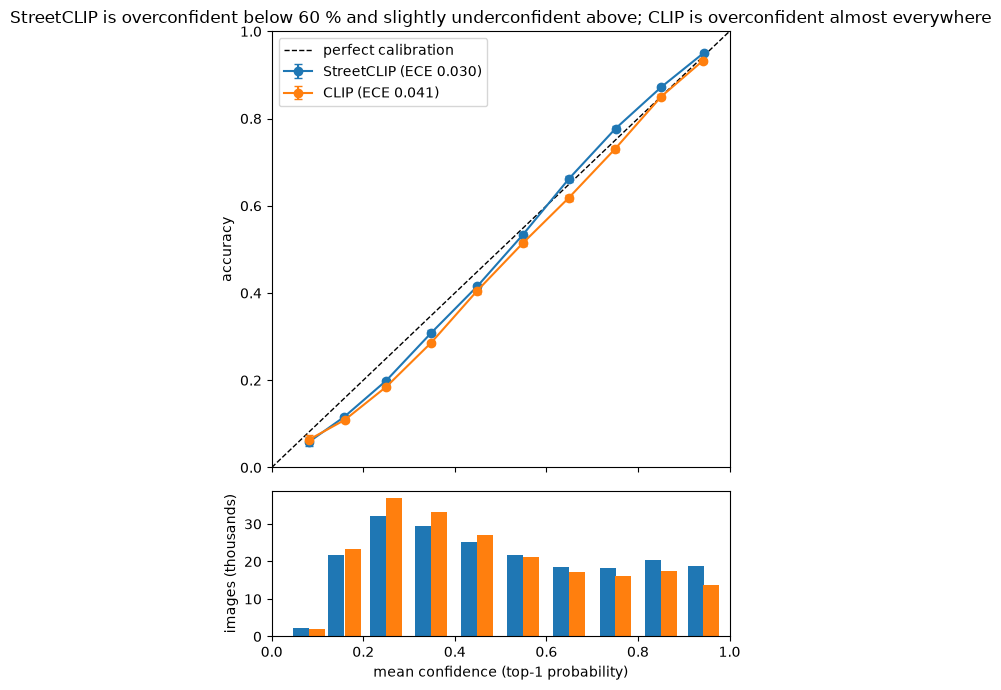

In [7]:
cal = {"StreetCLIP": q2.calibration_table(preds), "CLIP": q2.calibration_table(clip_preds)}
display(viz.show_table(cal["StreetCLIP"], {"n": "Images", "conf": "Mean confidence", "acc": "Accuracy"},
                       pct=["conf", "acc"], ci=("acc", "ci_low", "ci_high"), bar="n"))
q2.plot_reliability(cal, "StreetCLIP is overconfident below 60 % and slightly underconfident above; CLIP is overconfident almost everywhere");

### Q2.2 Where is the model confidently wrong?
- Per country: overconfidence = mean confidence - accuracy (> 0: overconfident)
- Confident: top-1 probability >= 0.8

In [8]:
sc_table = q2.country_table(preds, countries)
top_gap = sc_table[~sc_table.low_n].sort_values("gap", ascending=False).head(10)
display(viz.show_table(top_gap, {"name": "Country", "n": "Images", "acc": "Accuracy", "conf": "Mean confidence",
                                 "gap": "Overconfidence", "conf_wrong": "Confidently wrong"},
                       pct=["acc", "conf", "conf_wrong"], pts=["gap"], ci=("acc", "ci_low", "ci_high"), bar="gap",
                       index=False))
q2.plot_gap_map(sc_table).show()

Country,Images,Accuracy,95 % CI,Mean confidence,Overconfidence,Confidently wrong
Georgia,290,0.3 %,0.1 to 1.9 %,35.6 %,+35.3 pts,2.8 %
Lithuania,131,1.5 %,0.4 to 5.4 %,35.0 %,+33.5 pts,0.0 %
Swaziland,35,5.7 %,1.6 to 18.6 %,39.1 %,+33.3 pts,8.6 %
Kuwait,33,3.0 %,0.5 to 15.3 %,34.4 %,+31.4 pts,0.0 %
Palau,64,10.9 %,5.4 to 20.9 %,40.7 %,+29.8 pts,3.1 %
Chad,458,2.0 %,1.0 to 3.7 %,30.4 %,+28.4 pts,0.0 %
Slovenia,73,9.6 %,4.7 to 18.5 %,37.8 %,+28.2 pts,1.4 %
Mali,"1,226",1.9 %,1.3 to 2.8 %,29.5 %,+27.7 pts,0.1 %
Serbia,242,6.6 %,4.1 to 10.5 %,33.7 %,+27.0 pts,0.0 %
Slovakia,150,8.0 %,4.6 to 13.5 %,34.9 %,+26.9 pts,0.7 %


In [9]:
conf_err = q2.confident_errors(preds, countries)
q2.plot_confident_errors(conf_err, "Confident errors are mostly neighbours: US -> Canada is the largest pair (455 of 3,523)").show()

#### The Georgia case
- "Georgia" is a country (GE) and a US state
- Old prompt (template from the StreetCLIP paper): "A Street View photo in Georgia."
- New shared prompt (since 6 Nov, adds the subregion): "A Street View photo in Georgia, Western Asia."
- Old-prompt runs are kept in `results/shared/*_oldprompt`, made without re-running the images
  (`PredictionRunner.rescore` on the cached embeddings with the old template); the cells below skip them if missing
- Which US states are guessed as the country Georgia, with the old and the new prompt?
- Does the original CLIP (same prompt, before fine-tuning) make the same error?
- Images below: random, not hand-picked; shown as the model sees them (center crop)

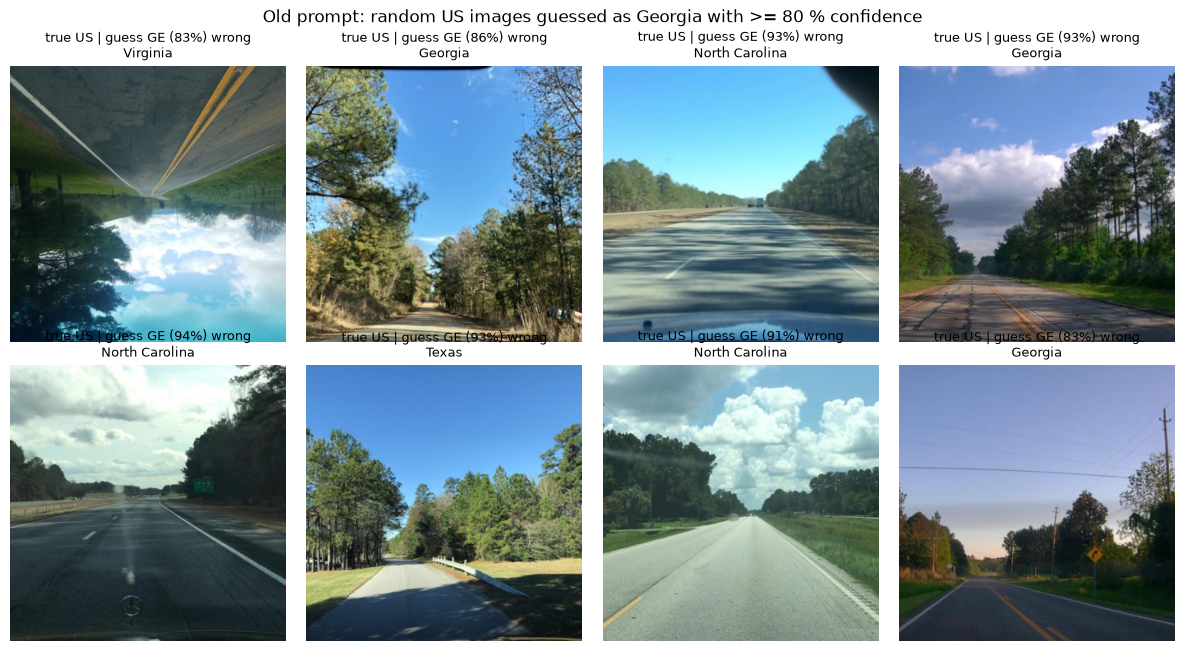

In [10]:
old_runs = {m: Path(f"results/shared/{m}_v1_center_crop_oldprompt/predictions.parquet")
            for m in ["clip", "streetclip"]}
have_old = all(p.exists() for p in old_runs.values())
if have_old:
    clip_old = pd.read_parquet(old_runs["clip"])
    preds_old = pd.read_parquet(old_runs["streetclip"])
    q2.plot_georgia_map(q2.georgia_states(preds_old),
                        "Old prompt: the country \"Georgia\" is guessed for the US South-East (89 % of the state of Georgia)").show()
    viz.image_grid(dataset, q2.confident_examples(preds_old, "US", "GE"),
                   "Old prompt: random US images guessed as Georgia with >= 80 % confidence", note="region");
else:
    print("Old-prompt runs not found (results/shared/*_oldprompt): only the new prompt is shown.")

q2.plot_georgia_map(q2.georgia_states(preds),
                    "New prompt (\"..., Western Asia.\"): only 4 % of the state of Georgia is still guessed as the country").show()

In [11]:
models = {"CLIP": clip_preds, "StreetCLIP": preds}   # new prompt
if have_old:
    models = {"CLIP, old prompt": clip_old, "StreetCLIP, old prompt": preds_old,
              "CLIP, new prompt": clip_preds, "StreetCLIP, new prompt": preds}
ge_cmp = q2.georgia_compare(models)   # within one prompt: same prompt for both models
display(viz.show_table(ge_cmp, {"us_to_ge": "US images guessed Georgia", "us_share": "Share of US images",
                                "us_to_ge_conf": "... with >= 80 % confidence",
                                "ge_guess_us": "Georgia guesses that are US",
                                "ge_right": "Real Georgia right", "ge_n": "Real Georgia images"},
                       pct=["us_share", "ge_guess_us"]))

,US images guessed Georgia,Share of US images,... with >= 80 % confidence,Georgia guesses that are US,Real Georgia right,Real Georgia images
"CLIP, old prompt","1,962",8.2 %,634,89.7 %,4,290
"StreetCLIP, old prompt","2,346",9.8 %,"1,126",96.3 %,0,290
"CLIP, new prompt",38,0.2 %,0,13.4 %,11,290
"StreetCLIP, new prompt",62,0.3 %,0,36.7 %,1,290


- Low precision: a label the model picks often, but wrongly
- Grey rows: country has no test images, so every guess of it is an error

In [12]:
pred_table = q2.predicted_table(preds, countries)
low_prec = pred_table[pred_table.n_pred >= 100].sort_values("precision").head(10)
display(viz.show_table(low_prec, {"name": "Guessed country", "n_pred": "Times guessed",
                                  "precision": "Right when guessed", "n_true": "Real test images",
                                  "top_source": "Most common real country", "top_source_n": "... images"},
                       pct=["precision"], bar="n_pred", grey=low_prec.n_true == 0, index=False))

Guessed country,Times guessed,Right when guessed,Real test images,Most common real country,... images
Namibia,999,0.0 %,0,South Africa,576
Gabon,328,0.0 %,7,Democratic Republic of the Congo,91
Guam,341,0.0 %,0,United States,96
Syria,579,0.0 %,1,Algeria,116
Nauru,342,0.0 %,0,Bahamas,60
Seychelles,100,0.0 %,0,Papua New Guinea,10
Eritrea,224,0.0 %,13,Pakistan,51
Andorra,219,0.0 %,0,Spain,48
San Marino,126,0.0 %,0,Italy,72
Swaziland,570,0.4 %,35,South Africa,115


### Q2.3 Training coverage
- Paper's training list: uncertain evidence (says 101 countries, lists 92)
- Idea: countries in the Street View training should gain most from fine-tuning (CLIP -> StreetCLIP)
- Box plot: one dot = one country (hover for the name)

In [13]:
groups = q2.training_groups(sc_table).rename(index={True: "on the paper's list", False: "not on the list"})
display(viz.show_table(groups, {"countries": "Countries", "images": "Images", "macro_acc": "Macro accuracy",
                                "acc_ci": "95 % CI (+/-)", "macro_conf": "Macro confidence",
                                "mean_gap": "Mean overconfidence"},
                       pct=["macro_acc", "acc_ci", "macro_conf"], pts=["mean_gap"]))
gain = q2.gain_table(sc_table, q2.country_table(clip_preds, countries))
q2.plot_gain_by_group(gain, "Mean gain a bit higher on the list (+3.0 vs. +1.2 points), same median (+2.2);<br>the groups overlap a lot").show()
q2.plot_gain(gain).show()

,Countries,Images,Macro accuracy,95 % CI (+/-),Macro confidence,Mean overconfidence
not on the list,85,"48,476",27.9 %,4.4 %,35.9 %,+8.0 pts
on the paper's list,86,"159,576",46.0 %,5.3 %,50.1 %,+4.1 pts


In [14]:
big = gain[~gain.low_n]
gain_cols = {"name": "Country", "n": "Images", "acc_clip": "CLIP", "acc": "StreetCLIP", "gain": "Gain"}
display(viz.show_table(big[~big.in_train_list].sort_values("gain", ascending=False).head(8), gain_cols,
                       pct=["acc_clip", "acc"], pts=["gain"], index=False))   # big gain, not in list
display(viz.show_table(big[big.in_train_list].sort_values("gain").head(8), gain_cols,
                       pct=["acc_clip", "acc"], pts=["gain"], index=False))   # in list, but no gain

Country,Images,CLIP,StreetCLIP,Gain
Guinea-Bissau,90,14.4 %,54.4 %,+40.0 pts
Moldova,182,25.3 %,63.2 %,+37.9 pts
Niger,260,20.0 %,49.6 %,+29.6 pts
Djibouti,162,42.6 %,70.4 %,+27.8 pts
El Salvador,114,0.9 %,28.1 %,+27.2 pts
East Timor,213,6.1 %,31.5 %,+25.4 pts
North Korea,37,56.8 %,81.1 %,+24.3 pts
Angola,"1,477",8.4 %,30.5 %,+22.1 pts


Country,Images,CLIP,StreetCLIP,Gain
Croatia,308,57.8 %,26.3 %,-31.5 pts
Bermuda,98,61.2 %,37.8 %,-23.5 pts
Finland,"2,280",94.1 %,72.4 %,-21.8 pts
Ukraine,48,29.2 %,8.3 %,-20.8 pts
Estonia,274,41.6 %,23.4 %,-18.2 pts
Uruguay,250,66.8 %,52.0 %,-14.8 pts
Swaziland,35,20.0 %,5.7 %,-14.3 pts
Uganda,837,40.4 %,26.5 %,-13.9 pts


- Numbers behind the Q2 findings: prompt change, Georgia details, training list with the original CLIP

In [15]:
# 1) Paper's prompt vs. new prompt: accuracy and confident errors
if have_old:
    rows = {}
    for label, p in {"paper's prompt (old)": preds_old, "with subregion (new)": preds}.items():
        u = q2.usable(p)
        rows[label] = {"acc": u["correct"].astype(float).mean(),
                       "conf_wrong": ((u["prob_1"] >= q2.CONF_HIGH) & ~u["correct"].astype(bool)).sum()}
    display(viz.show_table(pd.DataFrame.from_dict(rows, orient="index"),
                           {"acc": "Top-1 accuracy", "conf_wrong": "Wrong with >= 80 % confidence"}, pct=["acc"]))

# 2) Georgia with the new prompt: the US state and the real country
u = q2.usable(preds)
state = u[(u["country_id"] == "US") & (u["region"] == "Georgia")]
real = u[u["country_id"] == "GE"]
in_top5 = real[[f"pred_{i}" for i in range(1, 6)]].eq("GE").any(axis=1).mean()
print(f"State of Georgia: {(state['pred_1'] == 'US').mean():.0%} of {len(state)} images are guessed as the US")
print(f"Real Georgia: right {(real['pred_1'] == 'GE').sum()} of {len(real)}, in the top 5 for {in_top5:.0%}")
print("Real Georgia is guessed as:",
      ", ".join(f"{countries.loc[c, 'prompt_name']} ({k})" for c, k in real["pred_1"].value_counts().head(4).items()))

# 3) Training list: StreetCLIP vs. original CLIP, and the gain with both prompts
cov = pd.DataFrame({"sc": q2.training_groups(sc_table)["macro_acc"],
                    "clip": q2.training_groups(q2.country_table(clip_preds, countries))["macro_acc"]})
cov["gain_mean"] = big.groupby("in_train_list")["gain"].mean()
cov["gain_median"] = big.groupby("in_train_list")["gain"].median()
cov_cols = {"sc": "StreetCLIP macro accuracy", "clip": "CLIP macro accuracy",
            "gain_mean": "Mean gain", "gain_median": "Median gain"}
if have_old:
    gain_old = q2.gain_table(q2.country_table(preds_old, countries), q2.country_table(clip_old, countries))
    cov["gain_mean_old"] = gain_old[~gain_old.low_n].groupby("in_train_list")["gain"].mean()
    cov_cols["gain_mean_old"] = "Mean gain, paper's prompt"
cov = cov.rename(index={True: "on the paper's list", False: "not on the list"})
display(viz.show_table(cov, cov_cols, pct=["sc", "clip"], pts=[c for c in cov_cols if c.startswith("gain")]))

,Top-1 accuracy,Wrong with >= 80 % confidence
paper's prompt (old),50.8 %,"5,255"
with subregion (new),49.1 %,"3,523"


State of Georgia: 90% of 451 images are guessed as the US
Real Georgia: right 1 of 290, in the top 5 for 11%
Real Georgia is guessed as: Romania (39), Azerbaijan (34), Moldova (28), North Korea (20)


,StreetCLIP macro accuracy,CLIP macro accuracy,Mean gain,Median gain,"Mean gain, paper's prompt"
not on the list,27.9 %,26.7 %,+1.2 pts,+2.2 pts,+0.5 pts
on the paper's list,46.0 %,42.9 %,+3.0 pts,+2.2 pts,+5.3 pts


### Q2 findings
- **Prompt:** all numbers use the new shared prompt with the subregion ("A Street View photo in Georgia, Western Asia."). The paper's prompt ("... in Georgia.") is kept only as a comparison for the Georgia case. The new prompt costs 1.7 points of top-1 accuracy overall (50.8 % -> 49.1 %).
- **Calibration:** StreetCLIP is overconfident below 60 % confidence (up to +5 points) and slightly underconfident above (up to -2.6 points); ECE 0.030. The original CLIP is overconfident in almost every bin (ECE 0.041), so fine-tuning made the confidence more honest.
- **Confident errors:** 3,523 images are wrong with >= 80 % confidence (5,255 with the old prompt). The largest pairs are neighbours: US -> Canada (455), China -> US (223), US -> Mexico (205), Russia -> Finland (123).
- **Georgia:** with the paper's prompt the model read "Georgia" as the US state: 96 % of all "Georgia" guesses were US images (89 % of the images from the state of Georgia), 1,126 of them with >= 80 % confidence. The original CLIP made the same error (1,962 US images), so it comes from pretraining, and fine-tuning made it stronger. Adding the subregion removes it almost completely: only 62 US images are still guessed as Georgia (none with >= 80 % confidence), and 90 % of the state of Georgia is now correctly the US. But real Georgia is still almost never right (1 of 290, in the top 5 for 11 %; now mostly Romania, Azerbaijan, Moldova). So the prompt fixed the US confusion, not the recognition of Georgia.
- **Labels that are (almost) never right:** the labels guessed often but wrongly are small countries or neighbours with few or no test images. Namibia is guessed 999 times (576 of them South Africa), Gabon mostly for DR Congo (91 of 328), San Marino mostly for Italy (72 of 126), Andorra for Spain and France. Guam is mostly guessed for US images (96), Nauru and Seychelles for other islands (Bahamas, Papua New Guinea). So these are mostly near misses to a neighbour, not random errors (see also the attractors in Q1).
- **Training coverage:** countries on the paper's list are much more accurate (macro 46.0 % vs. 27.9 %). But most of this gap (16 of 18 points) already exists in the original CLIP (42.9 % vs. 26.7 %). Fine-tuning adds only a bit more on the list in the mean (+3.0 vs. +1.2 points) and nothing in the median (+2.2 for both), and the two groups overlap a lot. So the gain does not confirm the list (with the old prompt the gap in the mean was larger: +5.3 vs. +0.5).
- Open questions: why is real Georgia still almost never recognised? Why are 455 US images confidently guessed as Canada? Accuracy alone cannot settle the training list; Phase II could check if list countries are better separated in the image embeddings.

## Q3: Visual clues:
Which elements (text, road, vegetation, sky, ...) change the prediction when hidden, and does this differ between countries?

### Most important calculation

$$
\text{Adjusted effect}=\text{Real masking effect}-\text{Random control effect}
$$

For example, suppose the probability StreetCLIP gives the true country is initially 80%.
- After hiding vegetation: 50% (a drop of 30 percentage points).
- After random masking: 70% (a drop of 10 points).
- Adjusted effect: −30 − (−10) = −20 percentage points.

In [16]:
importlib.reload(q3)

q3cfg = q3.Q3Config(cap=60, focus_cap=150, n_controls=3)

q3cfg.focus_countries = q3.Q3Sampler.confused_countries(
    preds, n=20, min_images=q3cfg.focus_cap
)

sampler = q3.Q3Sampler(q3cfg, preds)
sample = sampler.build()
sample_ids = sample["id"].tolist()

Sample loaded from results/pair_a/q3/sample.csv (12,154 images)


### Q3.0 Masks (segmentation + text detection, once)

In [17]:
%%capture
builder = q3.Q3MaskBuilder(q3cfg, cfg, dataset)

In [18]:
%%capture
RUN_MASKS = False # True once: segmentation + OCR for the whole sample (resumes, skips cached images)

if RUN_MASKS:
    builder.segment(sample_ids)
    builder.detect_text(sample_ids)

presence = builder.presence(sample_ids)

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 1177.81it/s]


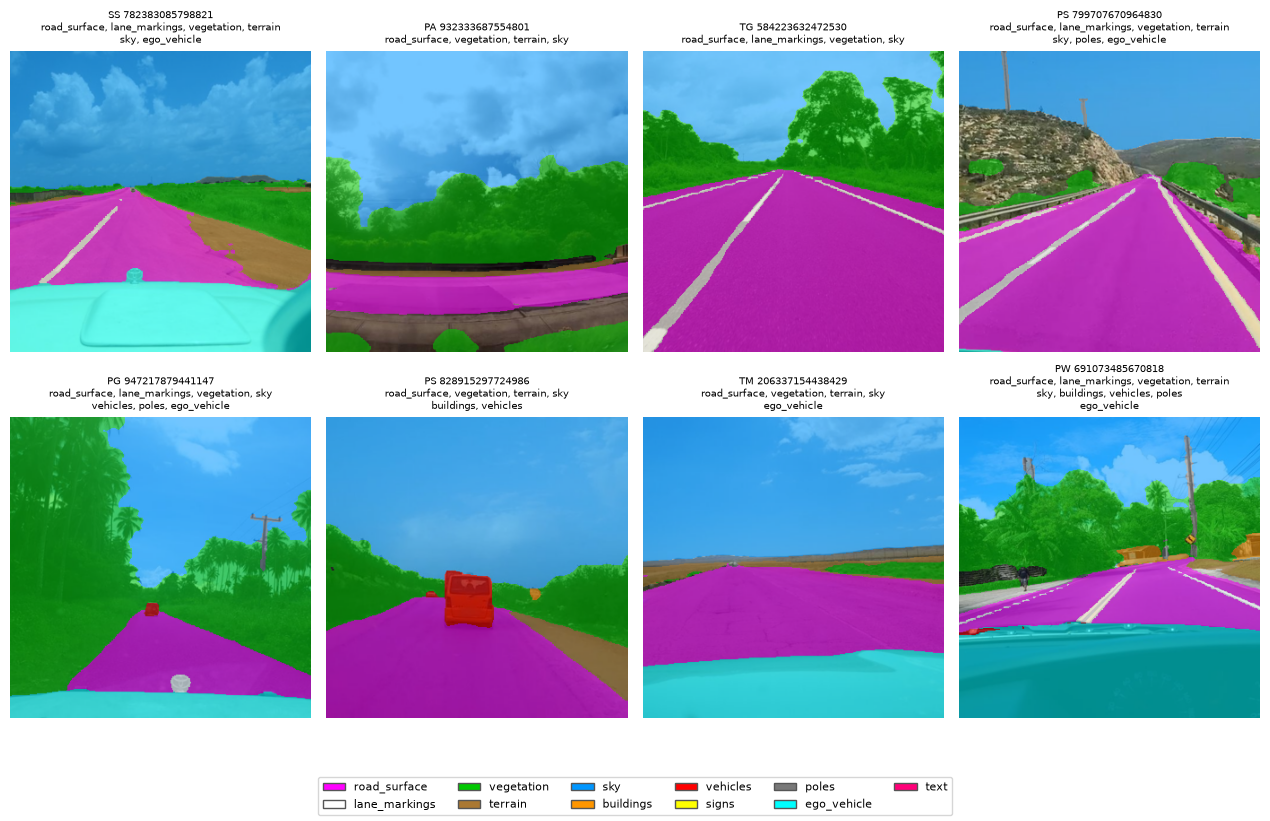

In [19]:
# StreetCLIP with exactly the candidates and prompts of the baseline run
model = GeoCLIPModel(cfg.streetclip_model, cfg)
model.set_candidates(info["labels"], mapper.prompts(info["labels"], info["prompt_template"]))
runner = q3.Q3Runner(q3cfg, cfg, dataset, presence)

# check the masks by eye: random images, as the model sees them
q3.Q3Reporter(None, runner).show_overlays(sample.sample(8, random_state=1)["id"].tolist());

### Q3.0 Masked runs

In [20]:
RUN_Q3 = False       # True once: all images (saved in chunks; after a crash it continues)
if RUN_Q3:
    runner.run(model, sample_ids)          # run name = fill mode ("gray")

q3_rows, q3_logits, q3_settings = q3.Q3Runner.load(runner.run_dir(cfg.fill_mode))
print(f"{q3_rows['id'].nunique():,} images, {len(q3_rows):,} versions")
display(q3.Q3Runner.check_original(q3_rows, q3_logits, q3_settings["labels"], preds, logits))

9,000 images, 320,740 versions


images                9000.000000
top1_agreement           0.998556
max_abs_logit_diff       0.119255
dtype: float64

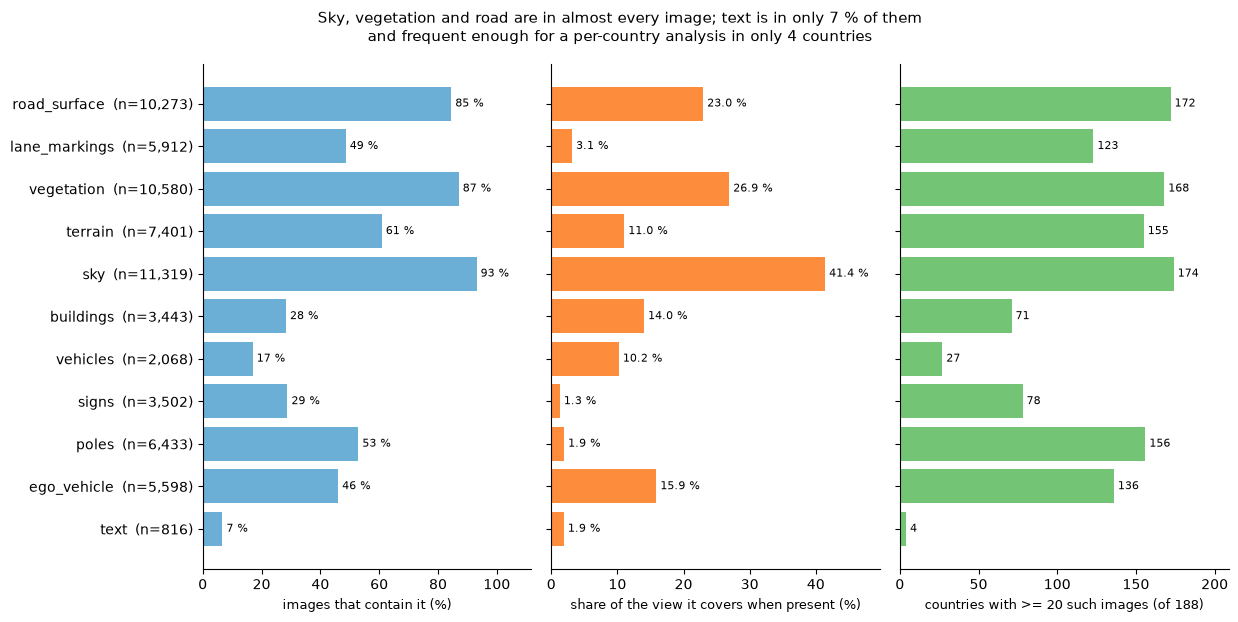

In [21]:
ana3 = q3.Q3Analyser(q3cfg, q3_rows, q3_logits, q3_settings["labels"], sample, mapper.table,
                     presence=presence, baseline_preds=preds)
rep3 = q3.Q3Reporter(ana3, runner)
presence_tab = ana3.presence_overview()    # how often each element is there -> how far we can split by country
rep3.plot_presence(presence_tab,
                   title="Sky, vegetation and road are in almost every image; text is in only 7 % of them\n"
                         "and frequent enough for a per-country analysis in only 4 countries");

### Q3.1 Which elements change the prediction?
- Macro average: every country counts once; pooled (every image) as a supplement
- Table: every hidden condition (real mask, random control, difference with 95 % CI)
- Plots: one row per visual element, same order in both (the parts follow in Q3.2, combinations in Q3.5)

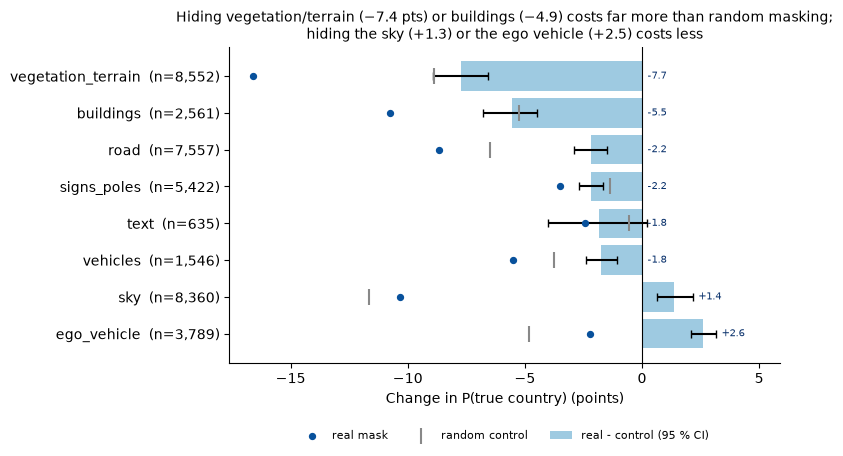

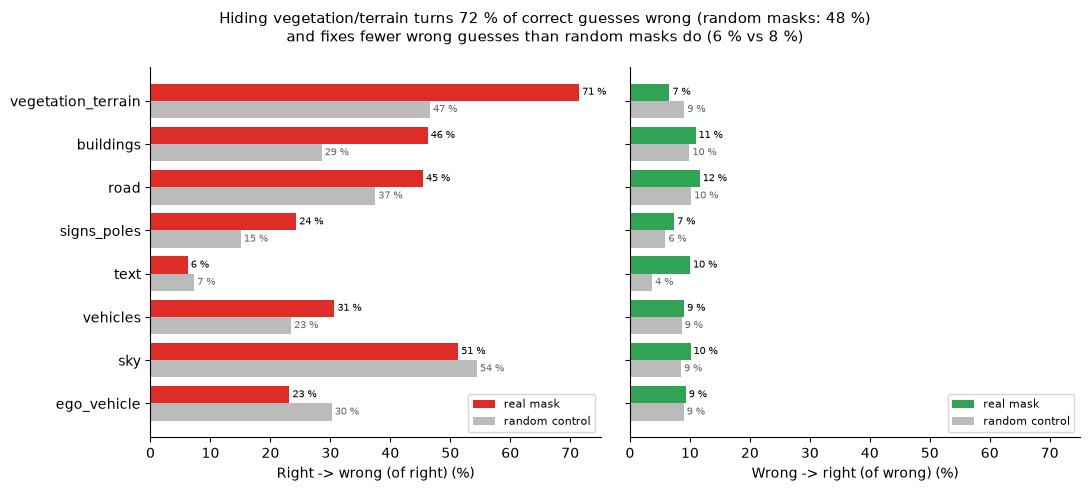

In [22]:
s_macro = ana3.summary()                                   # d_true, d_orig, flip, r2w, w2r
s_pooled = ana3.summary(level="pooled")
#display(rep3.table(s_macro))                               # reference table: all conditions

coarse = q3.subset(s_macro, q3.COARSE)                     # one row per visual element
order = q3.effect_order(coarse)                            # strongest effect on top, used by both plots
rep3.plot_effects(coarse, "d_true", order=order,
                  title="Hiding vegetation/terrain (−7.4 pts) or buildings (−4.9) costs far more than random masking;\n"
                        "hiding the sky (+1.3) or the ego vehicle (+2.5) costs less");
rep3.plot_flips(coarse, order=order,
                title="Hiding vegetation/terrain turns 72 % of correct guesses wrong (random masks: 48 %)\n"
                      "and fixes fewer wrong guesses than random masks do (6 % vs 8 %)");

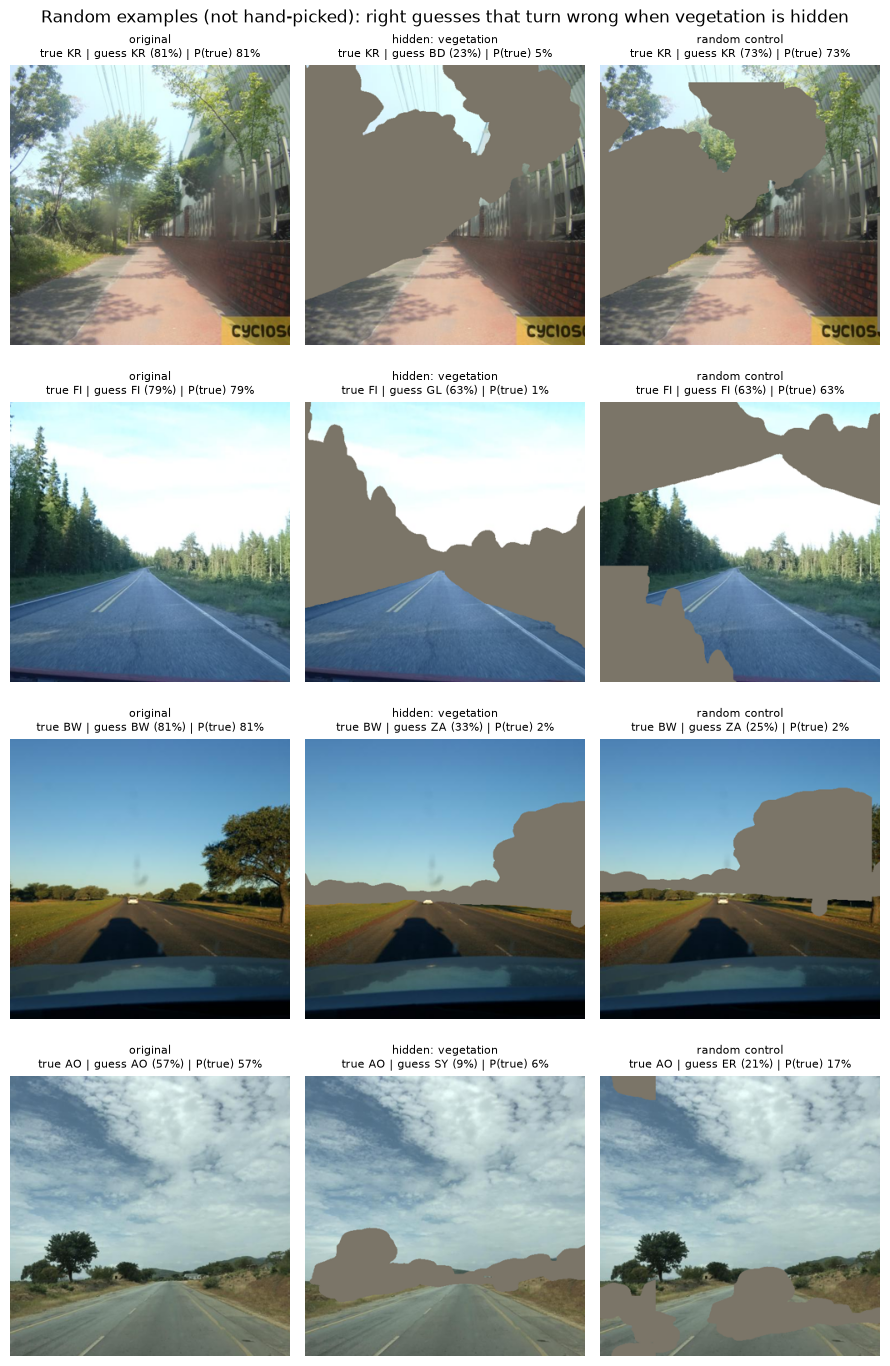

In [23]:
# random examples (not hand-picked): right -> wrong when vegetation, the strongest cue, is hidden
rep3.show_examples("vegetation", which="r2w", n=4);

### Q3.2 Split clues: road surface vs lane markings, signs vs poles, vegetation vs terrain
- Left: each whole element (grey) and its parts; right: effect vs share of the view that is hidden
- The parts occur in different sets of images, so this is not a controlled per-pixel ranking

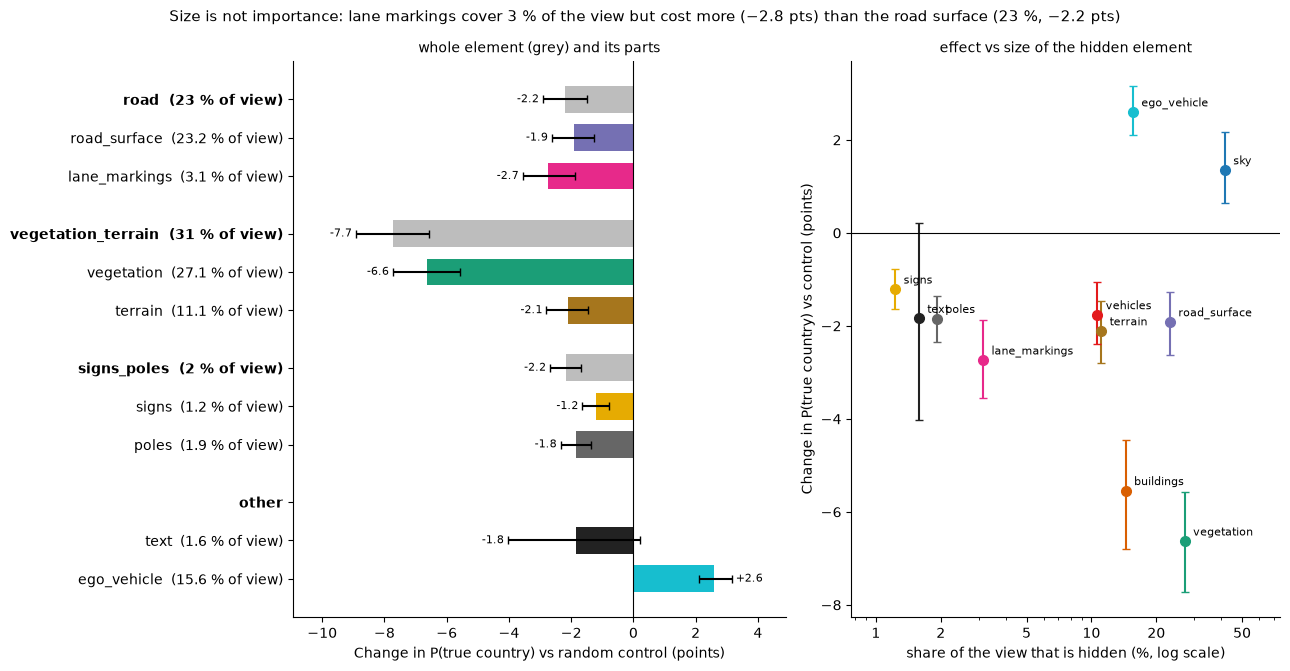

In [24]:
split = ["road", "road_surface", "lane_markings", "vegetation_terrain", "vegetation", "terrain",
         "signs_poles", "signs", "poles", "text", "ego_vehicle", "sky", "buildings", "vehicles"]
rep3.plot_split(q3.subset(s_macro, split),
                title="Size is not importance: lane markings cover 3 % of the view but cost more (−2.8 pts) "
                      "than the road surface (23 %, −2.2 pts)");

### Q3.3 Does the model lose confidence, does its probability spread out?
- `correct0`: images that were right vs wrong before hiding
- Confidence = top-1 probability; entropy = how spread out the probabilities are (bits, higher = less certain)
- Flips and wrong -> right: see Q3.1

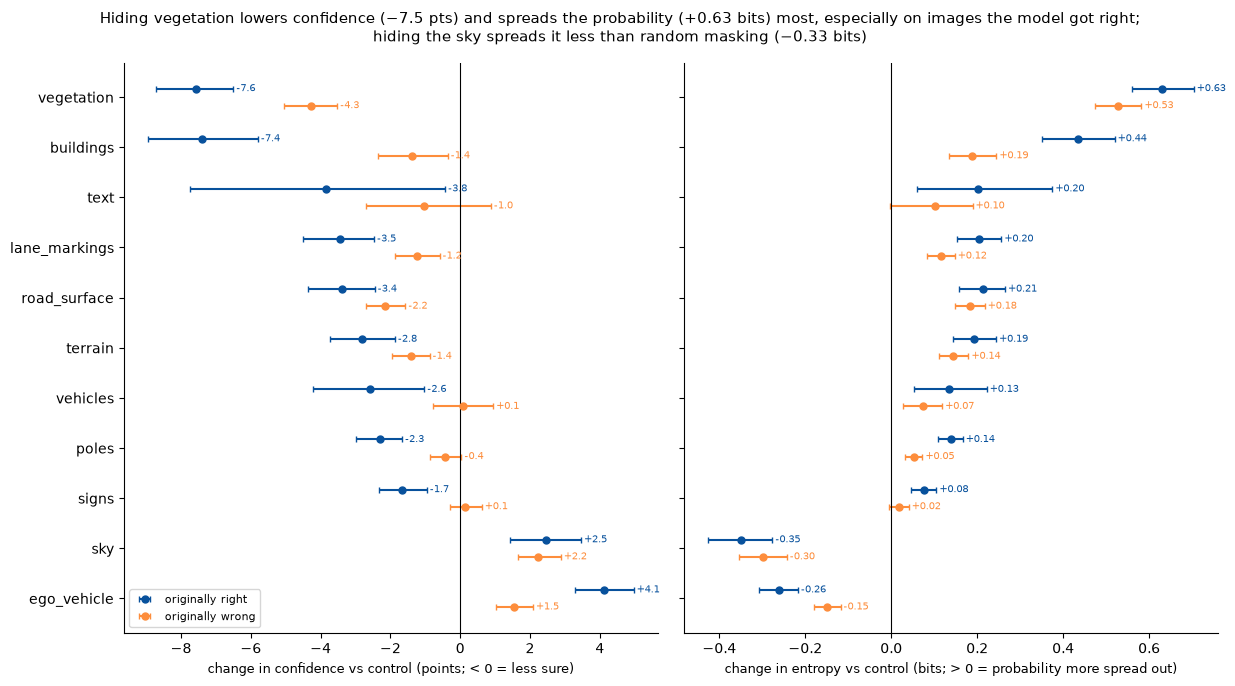

In [25]:
conf = ana3.summary(metrics=("d_conf", "d_entropy"), by="correct0", conditions=list(q3.FINE))
rep3.plot_confidence(conf,
                     title="Hiding vegetation lowers confidence (−7.5 pts) and spreads the probability (+0.63 bits) most, "
                           "especially on images the model got right;\n"
                           "hiding the sky spreads it less than random masking (−0.33 bits)");

### Q3.4 Neighbours and usual confusions
- Where do the new errors land (right -> wrong flips; every flip counts once): a land neighbour, the same
  subregion, or one of the 5 most frequent wrong guesses of the true country (full test set)?
  Dashed line: where the model's own errors on the unmasked images land
- Where does the probability go: true country, its land neighbours, its usual confusions (pooled)
- Which country pairs does hiding an element create (sorted by real minus control)?

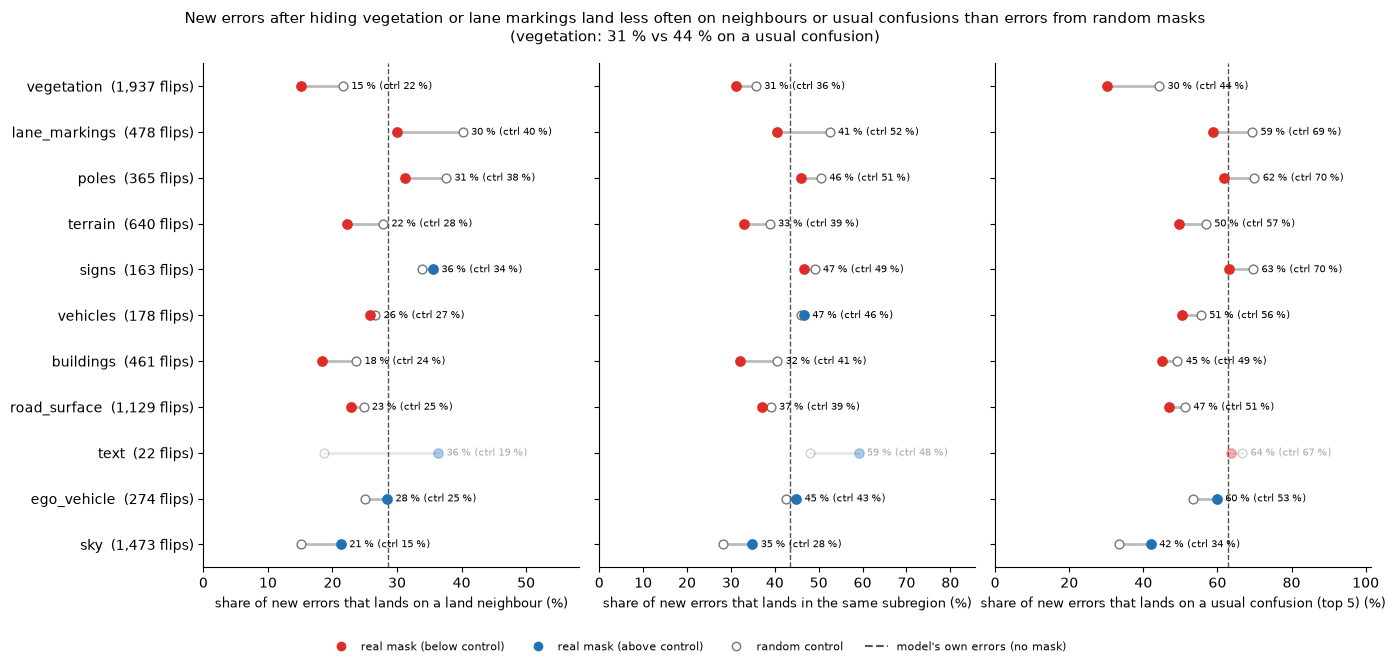

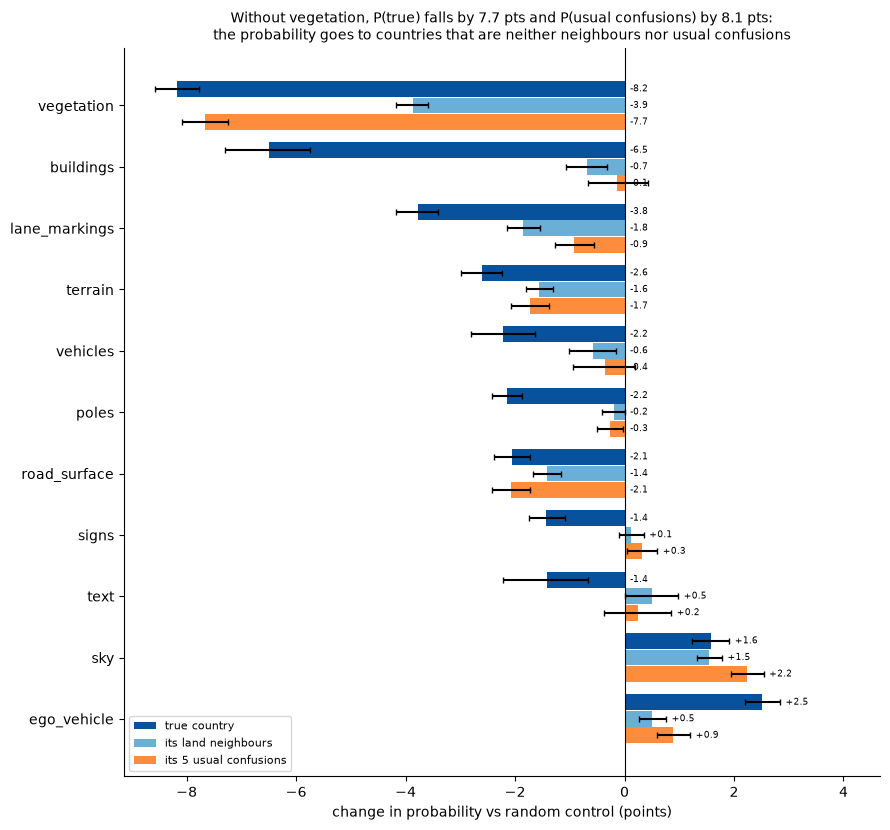

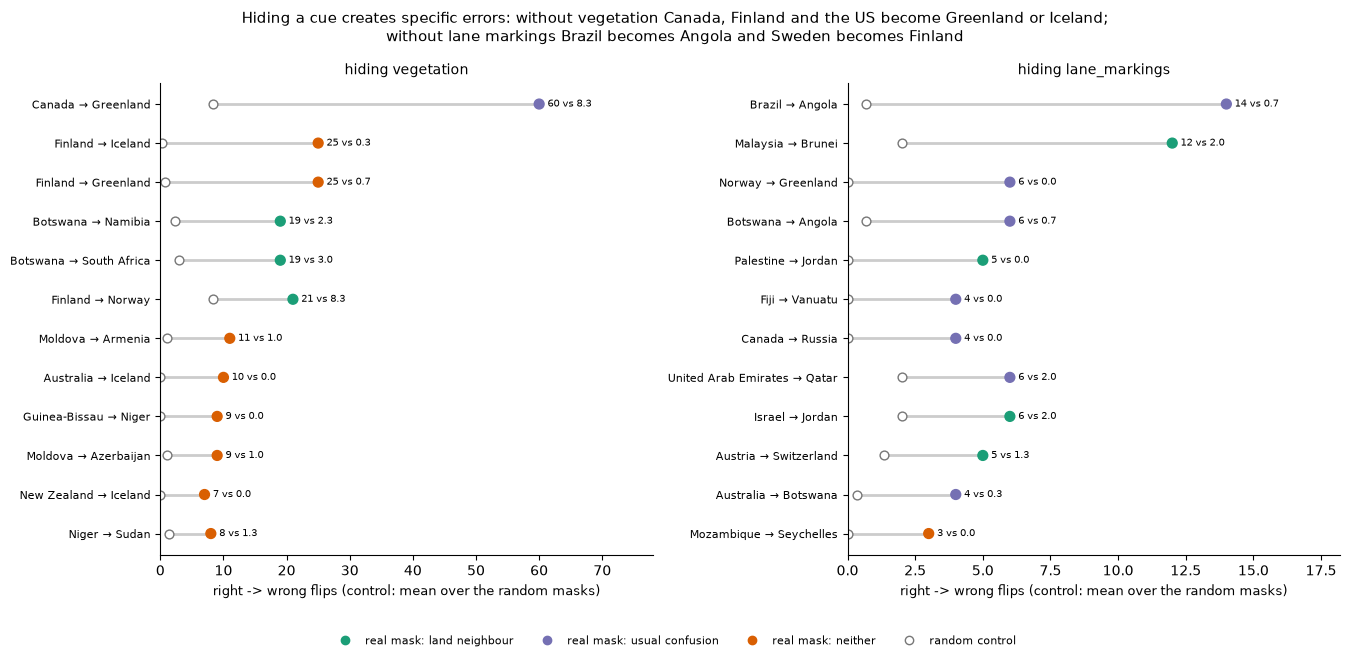

In [26]:
shift = ana3.confusion_shift()                       # pooled
rep3.plot_destinations(shift, conditions=list(q3.FINE),
                       title="New errors after hiding vegetation or lane markings land less often on neighbours or usual "
                             "confusions than errors from random masks\n(vegetation: 31 % vs 44 % on a usual confusion)");

shift_p = ana3.summary(("d_true", "d_nb", "d_sim"), level="pooled", conditions=list(q3.FINE))
rep3.plot_probability_shift(shift_p,
                            title="Without vegetation, P(true) falls by 7.7 pts and P(usual confusions) by 8.1 pts:\n"
                                  "the probability goes to countries that are neither neighbours nor usual confusions");

rep3.plot_flip_pairs(["vegetation", "lane_markings"], top=12,
                     title="Hiding a cue creates specific errors: without vegetation Canada, Finland and the US become "
                           "Greenland or Iceland;\nwithout lane markings Brazil becomes Angola and Sweden becomes Finland");

### Q3.5 Do cues compensate each other?
- extra = effect(both hidden) - (effect A + effect B), control-corrected; > 0 = hiding both hurts more than
  the two alone (when one is hidden, the other still carries the information)

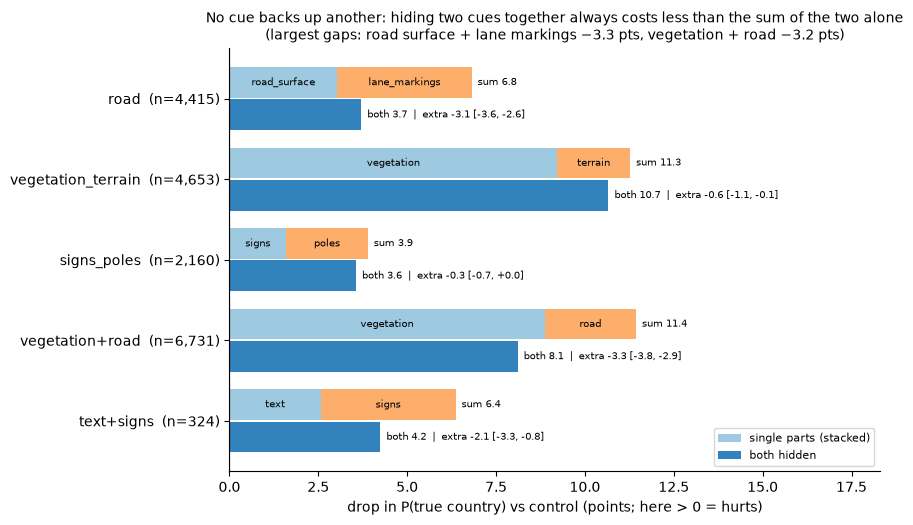

In [27]:
inter = ana3.interactions()
rep3.plot_interactions(inter,
                       title="No cue backs up another: hiding two cues together always costs less than the sum of the two "
                             "alone\n(largest gaps: road surface + lane markings −3.3 pts, vegetation + road −3.2 pts)");

### Q3.6 Which cue matters where?
- Strongest cue per country (control-corrected change of P(true), 95 % CI over camera sequences; hollow = CI crosses 0)
- Country x element for these countries and the 20 focus countries; only cells with >= 20 images containing the element
- Rare elements (text, signs, lane markings): by subregion

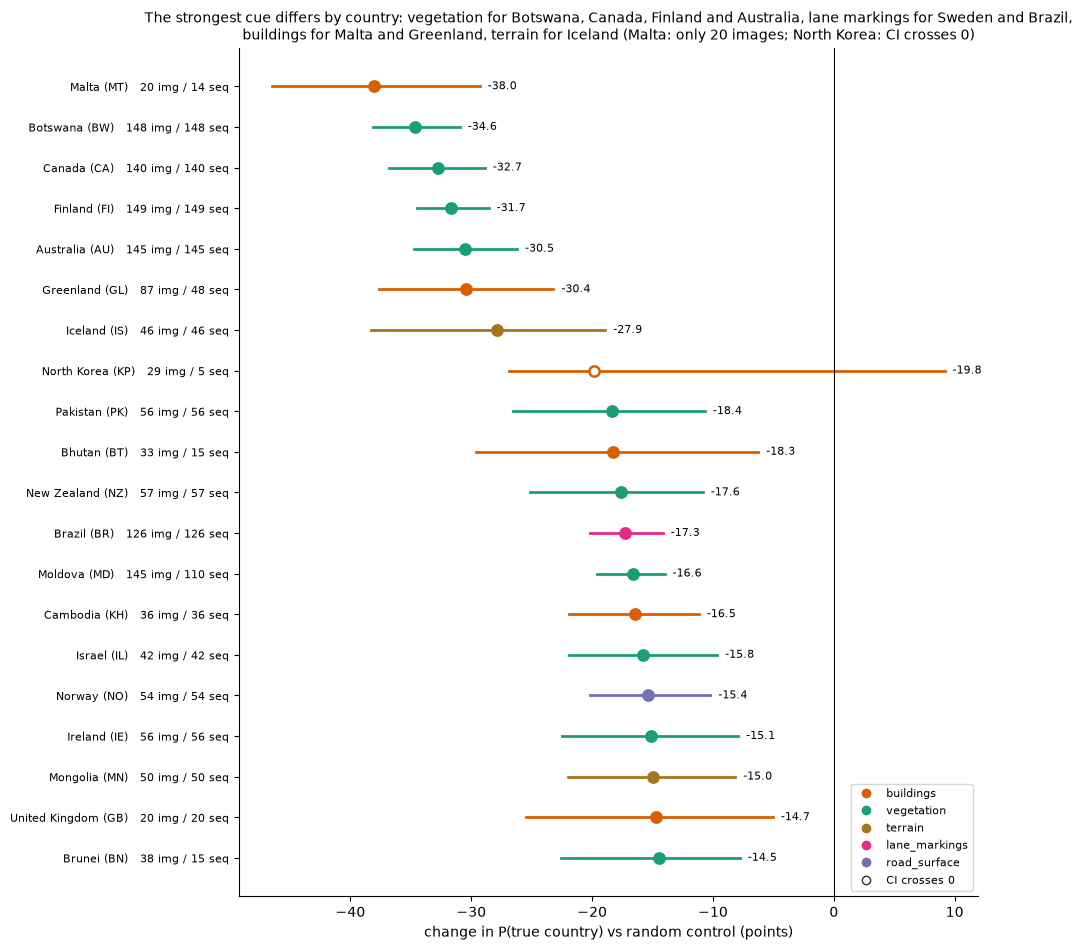

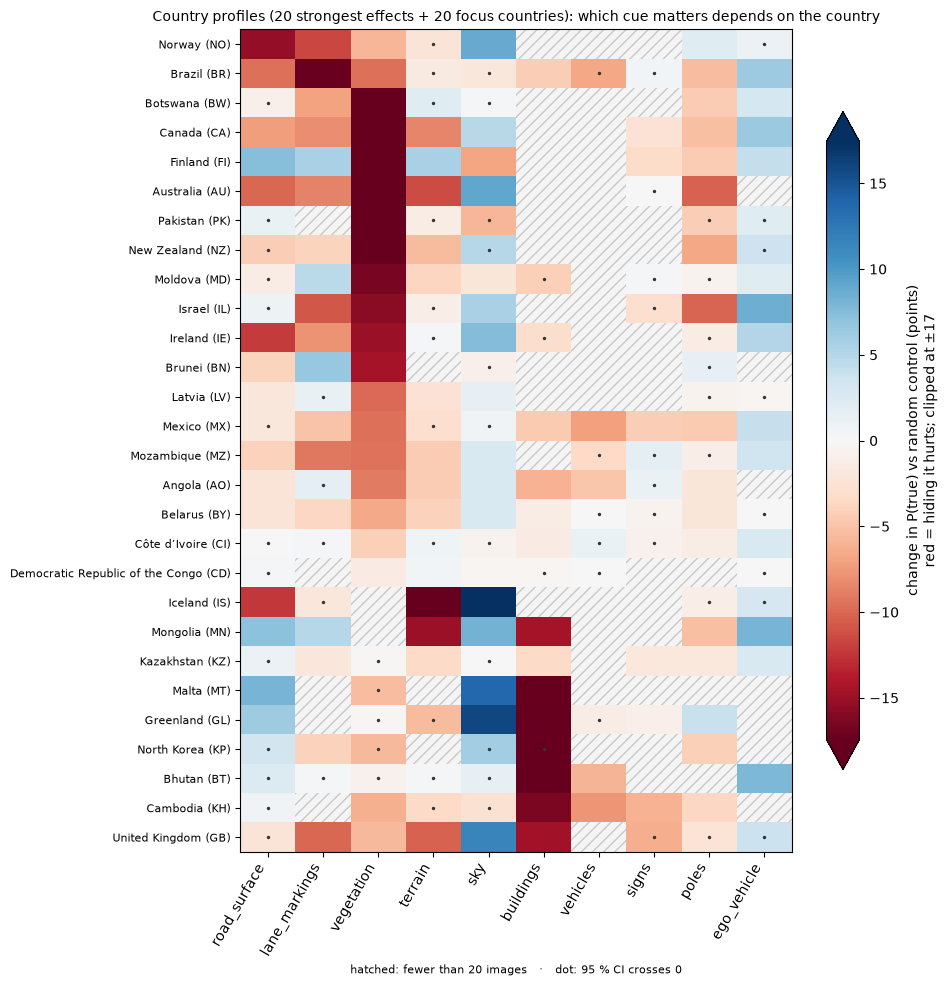

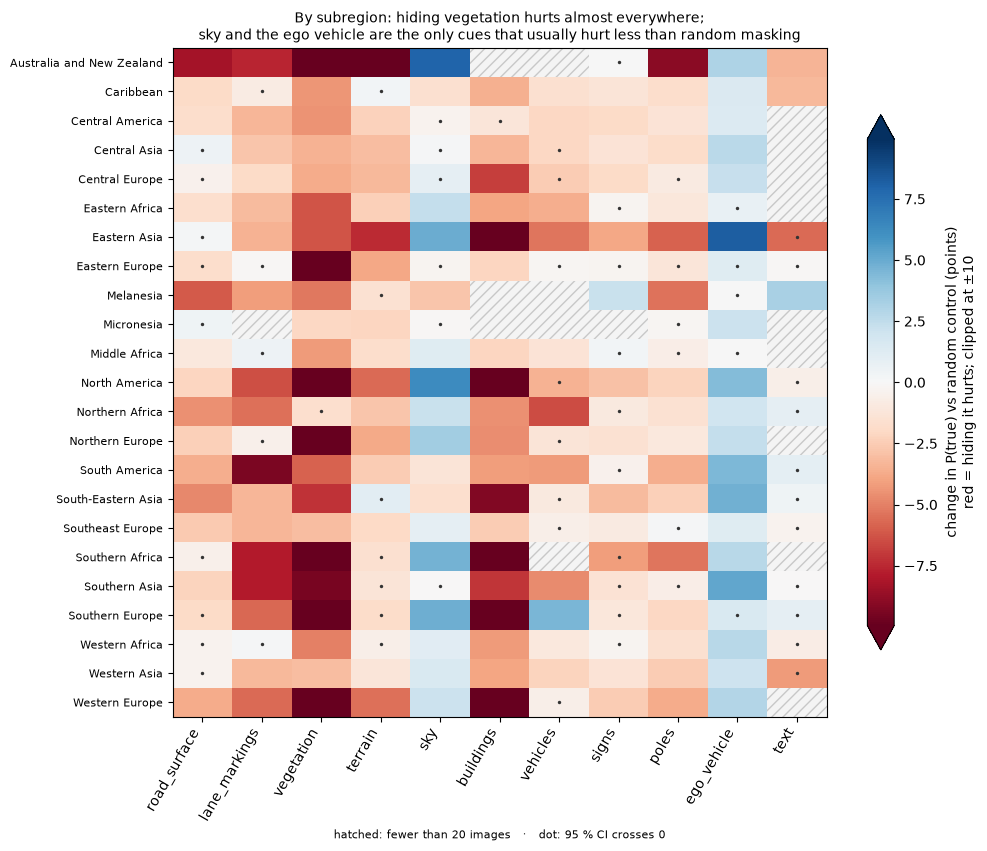

In [28]:
prof = ana3.country_profile("d_true")
cues = ["road_surface", "lane_markings", "vegetation", "terrain", "buildings", "signs", "poles", "text"]
strongest = ana3.strongest_cue(prof, conditions=cues)
rep3.plot_strongest(strongest, top=20,
                    title="The strongest cue differs by country: vegetation for Botswana, Canada, Finland and Australia, "
                          "lane markings for Sweden and Brazil,\nbuildings for Malta and Greenland, terrain for Iceland "
                          "(Malta: only 20 images; North Korea: CI crosses 0)");

show = list(dict.fromkeys(list(strongest.index[:20]) + list(q3cfg.focus_countries)))
rep3.plot_heatmap(prof, conditions=[c for c in q3.FINE if c != "text"], rows=show, sort_by="strongest",
                  title="Country profiles (20 strongest effects + 20 focus countries): which cue matters depends on the country");

prof_sub = ana3.country_profile("d_true", group="world_subregion")
rep3.plot_heatmap(prof_sub, conditions=list(q3.FINE),
                  title="By subregion: hiding vegetation hurts almost everywhere;\n"
                        "sky and the ego vehicle are the only cues that usually hurt less than random masking");

### Q3.7 Does the effect change by environment?
- Same idea as Q4: environment and country are mixed up, so next to the pooled effect (left) the plots show the
  within-country difference (right: category effect minus the country's own effect, averaged over countries)

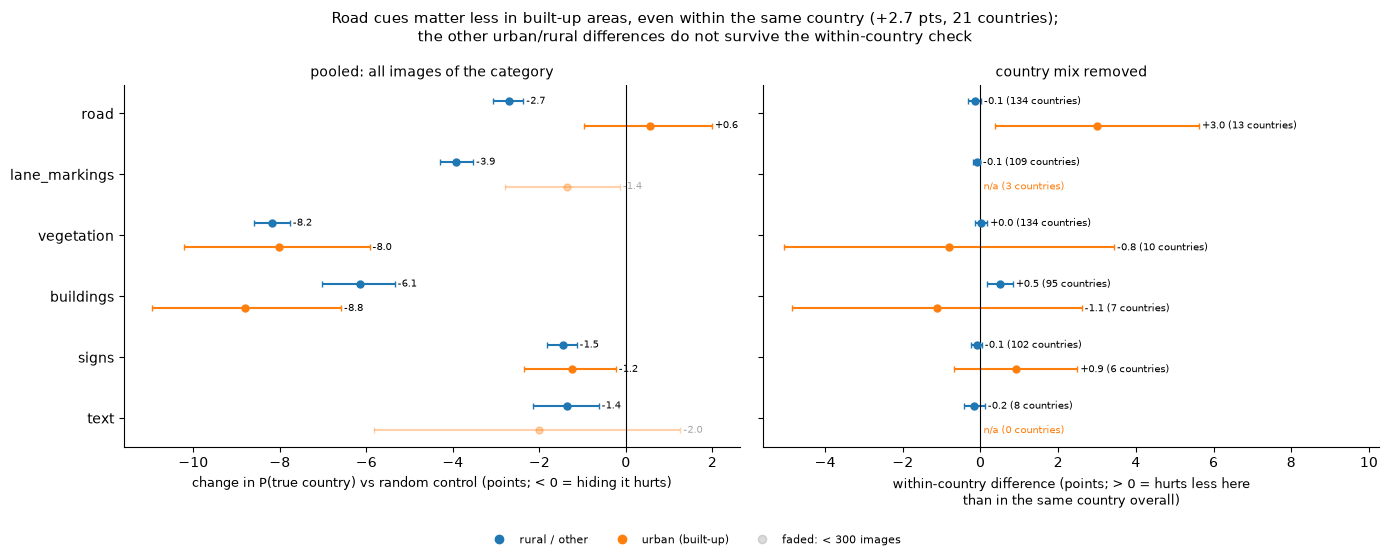

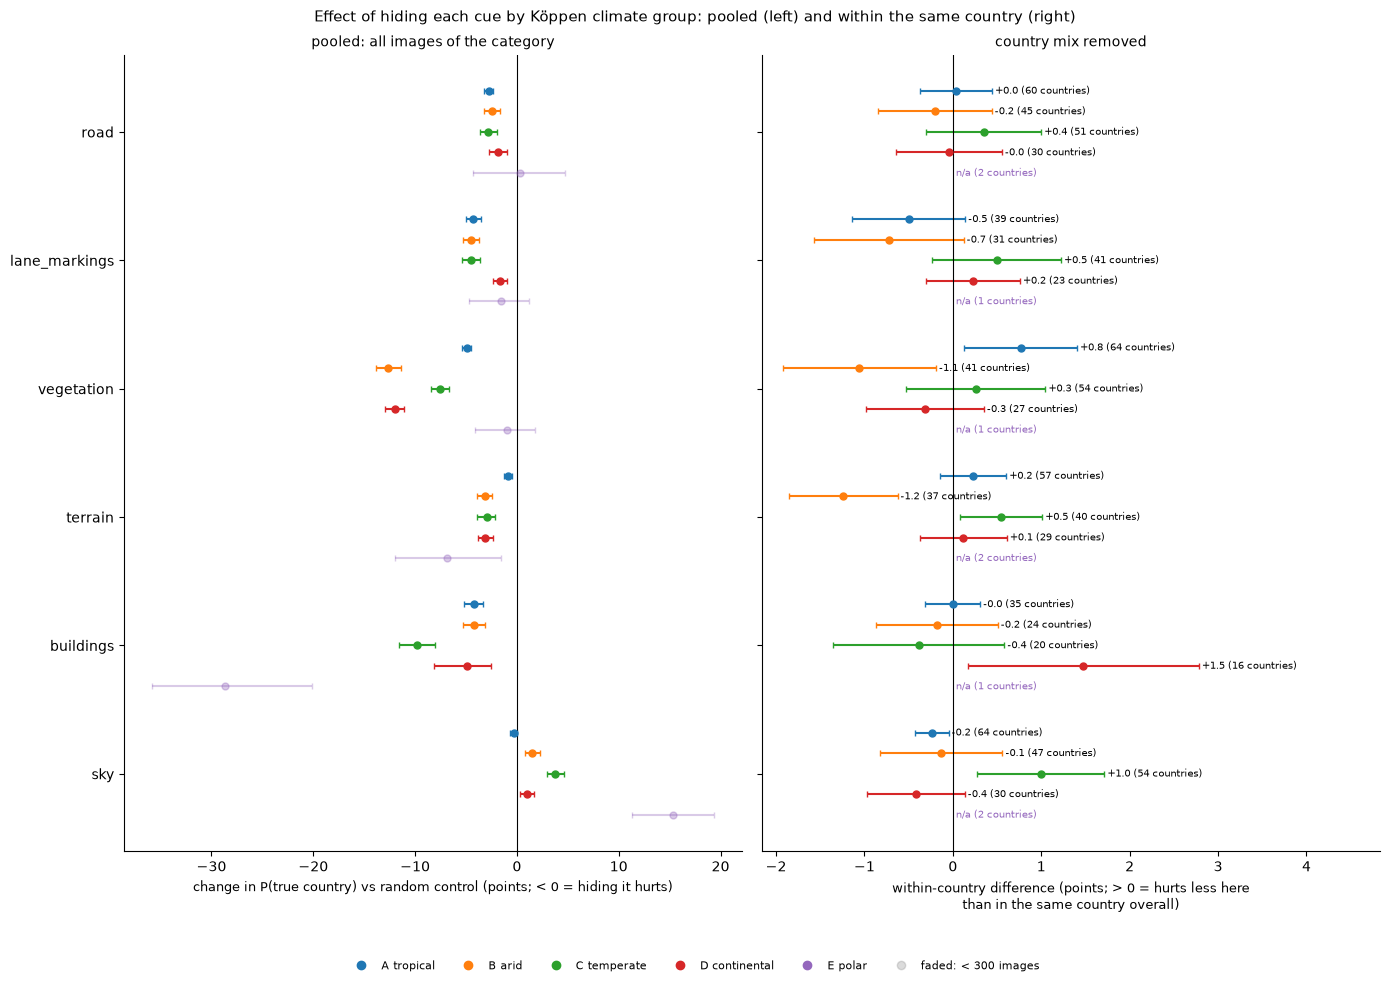

In [29]:
from pair_a import q4_environment as q4
env = q4.add_env_columns(preds)
urban_eff = ana3.environment(env, "urban")
rep3.plot_environment(urban_eff, "urban",
                      conditions=["road", "lane_markings", "vegetation", "buildings", "signs", "text"],
                      title="Road cues matter less in built-up areas, even within the same country (+2.7 pts, 21 countries);\n"
                            "the other urban/rural differences do not survive the within-country check");
climate_eff = ana3.environment(env, "climate_group")
rep3.plot_environment(climate_eff, "climate_group",
                      conditions=["road", "lane_markings", "vegetation", "terrain", "buildings", "sky"],
                      title="Effect of hiding each cue by Köppen climate group: pooled (left) and within the same country (right)");

In [30]:
del model
free_gpu_memory()

### Q3 findings
- **Hidden cues matter beyond "less image".** Hiding vegetation/terrain lowers P(true country) by 7.4 pts more than
  a random mask of the same size, buildings by 4.9 pts; 72 % of correct guesses turn wrong without vegetation/terrain
  (random masks: 48 %). Hiding the sky (+1.3 pts) or the ego vehicle (+2.5 pts) hurts *less* than random masking.
- **Size is not importance.** Lane markings cover 3 % of the view but cost 2.8 pts, more than the road surface
  (23 % of the view, 2.2 pts).
- **Less certainty.** Without vegetation the model is less sure (−7.5 pts confidence on images it got right) and its
  probability is more spread out (+0.63 bits).
- **Different errors.** New errors after hiding vegetation land less often on usual confusions than errors from random
  masks (31 % vs 44 %); specific pairs appear (Canada → Greenland 60 vs 8.3, Finland → Iceland 24 vs 0.3; without lane
  markings Brazil → Angola 14 vs 0.7).
- **No backup between cues.** Hiding two cues together always costs less than the sum of the two alone (road surface +
  lane markings: −3.3 pts): the cues overlap or the damage saturates.
- **Country-dependent.** Strongest cue: vegetation for Botswana (−34.6 pts), Canada (−32.7), Finland (−31.7) and
  Australia (−30.5); lane markings for Sweden (−28.7) and Brazil (−17.3); terrain for Iceland (−27.9). Malta (20 images)
  and North Korea (5 sequences, CI crosses 0) are weak evidence.
- **Environment: be careful.** Road cues matter less in built-up areas even within countries (+2.7 pts, 21 countries);
  the urban/rural gaps for vegetation and buildings disappear in the within-country check.
- **Limits.** Gray masks, segmentation errors (e.g. dirt roads labelled as terrain) and overlapping cues: the results
  show how sensitive the model is to these interventions, not proof that it relies on the cue causally.

## Q4: Environment
Do accuracy and confidence vary with climate, land cover, distance to the sea, or urban vs. rural setting?
- Problem: environment and country are mixed up (a climate is mostly a few countries)
- **Expected from country mix**: accuracy we would get if only the country mattered
  (each image gets the accuracy of its country; big countries count more)
- **Within-country difference**: category accuracy minus its own country's accuracy, every country counts once
- Actual close to expected: the country mix explains it, not the environment

In [31]:
from pair_a import q4_environment as q4

env = q4.add_env_columns(preds)   # adds climate_group, urban (built-up or not), sea_bin

### Q4.1 Land cover
- First: who is in each class? Then: actual vs. expected accuracy

In [32]:
lc = q4.effect_table(env, "land_cover_name").drop(index="no data")
display(q4.show_effects(lc))
q4.plot_country_mix(env[env.land_cover_name != "no data"], "land_cover_name",
                    "Who is in each land cover class? Half of \"sparse vegetation\" is Australia").show()
q4.plot_expected(lc, "Land cover: built-up areas beat their country mix by 11 points;<br>the other large classes stay within 5 points").show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
artificial surfaces,"10,392",136,62.3 %,61.4 to 63.3 %,51.5 %,+10.9 pts,+7.2 pts,71.6 %
bare soil,"10,745",81,33.9 %,33.0 to 34.8 %,35.9 %,-2.0 pts,-6.5 pts,40.9 %
cropland,"71,833",169,49.5 %,49.1 to 49.8 %,47.5 %,+2.0 pts,+1.8 pts,55.7 %
grassland,"22,977",152,46.8 %,46.1 to 47.4 %,48.9 %,-2.1 pts,-2.1 pts,38.6 %
"herbaceous, flooded","2,639",52,57.8 %,55.9 to 59.7 %,56.9 %,+1.0 pts,+0.4 pts,43.8 %
mangroves,191,29,40.3 %,33.6 to 47.4 %,43.7 %,-3.4 pts,,
shrubs,"19,622",110,41.5 %,40.8 to 42.2 %,44.9 %,-3.4 pts,-3.2 pts,42.2 %
snow and glaciers,91,8,74.7 %,64.9 to 82.5 %,59.0 %,+15.8 pts,,
sparse vegetation,"9,467",65,64.4 %,63.5 to 65.4 %,65.5 %,-1.0 pts,-3.9 pts,45.2 %
tree covered,"53,791",161,50.2 %,49.8 to 50.6 %,51.8 %,-1.6 pts,-5.2 pts,34.4 %


### Q4.2 Climate
- Köppen main groups (A tropical ... E polar)

In [33]:
groups_order = list(q4.CLIMATE_GROUPS.values())
cl = q4.effect_table(env, "climate_group")
display(q4.show_effects(cl))
q4.plot_country_mix(env, "climate_group", "Who is in each climate group?", order=groups_order).show()
q4.plot_expected(cl, "Climate: A to D are within 2.5 points of what the country mix predicts", order=groups_order).show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
A tropical,"52,436",99,34.6 %,34.2 to 35.0 %,36.5 %,-1.9 pts,-2.5 pts,29.1 %
B arid,"52,654",88,49.3 %,48.9 to 49.7 %,49.8 %,-0.5 pts,-0.8 pts,32.4 %
C temperate,"50,087",100,54.6 %,54.2 to 55.1 %,52.1 %,+2.5 pts,-0.3 pts,48.1 %
D continental,"48,590",60,58.4 %,58.0 to 58.9 %,58.1 %,+0.3 pts,-2.7 pts,41.3 %
E polar,"1,876",27,60.6 %,58.4 to 62.8 %,68.4 %,-7.8 pts,-11.4 pts,16.7 %


### Q4.3 Distance to the sea
- `dist_sea`: 0 = at the coast, 1 = far inland (capped; landlocked countries have median 1.0)
- OSV-5M does not document the unit, so we use fixed bins

In [34]:
sea = q4.effect_table(env, "sea_bin")
display(q4.show_effects(sea))
q4.plot_expected(sea, "Distance to the sea: small effects (coast -4 points, far inland +2), mostly in big countries",
                 order=q4.SEA_LABELS).show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
0-0.05 (coast),"24,629",144,50.0 %,49.3 to 50.6 %,53.6 %,-3.7 pts,-1.5 pts,41.5 %
0.05-0.25,"28,153",136,52.5 %,51.9 to 53.1 %,52.4 %,+0.1 pts,+0.3 pts,45.8 %
0.25-0.5,"17,831",116,50.6 %,49.8 to 51.3 %,51.6 %,-1.0 pts,-0.0 pts,55.6 %
0.5-0.9,"28,892",115,47.6 %,47.1 to 48.2 %,49.1 %,-1.5 pts,-1.0 pts,44.3 %
0.9-0.99,"25,827",92,49.7 %,49.1 to 50.4 %,49.1 %,+0.6 pts,-0.7 pts,50.0 %
0.99-1 (inland),"82,982",90,47.8 %,47.4 to 48.1 %,46.2 %,+1.6 pts,-0.4 pts,47.4 %


### Q4.4 Urban vs. rural
- No urban column in OSV-5M. Proxy: land cover "artificial surfaces" (built-up area)
- `road_index` is not usable: it has only one value per country
- Check: one vote per camera sequence, so a long drive does not count many times

In [35]:
ur = q4.effect_table(env, "urban")
ur_seq = q4.effect_table(q4.per_sequence(env, "urban"), "urban")
display(q4.show_effects(pd.concat({"per image": ur, "per sequence": ur_seq})))

- Per country (>= 20 images in both groups); grey rows: fewer than 10 built-up sequences (weak evidence, not on the map)

Country,Built-up images,Built-up sequences,Accuracy built-up,Accuracy other,Difference
Papua New Guinea,26,12,11.5 %,49.9 %,-38.4 pts
Botswana,26,14,50.0 %,83.8 %,-33.8 pts
Peru,39,14,10.3 %,42.9 %,-32.7 pts
Angola,36,14,8.3 %,31.1 %,-22.8 pts
Somalia,30,6,83.3 %,100.0 %,-16.7 pts


Country,Built-up images,Built-up sequences,Accuracy built-up,Accuracy other,Difference
Iraq,44,26,68.2 %,32.2 %,+35.9 pts
China,762,301,80.8 %,39.6 %,+41.2 pts
Mali,28,13,46.4 %,0.8 %,+45.6 pts
Afghanistan,100,20,97.0 %,37.5 %,+59.5 pts
Libya,54,7,88.9 %,22.2 %,+66.7 pts


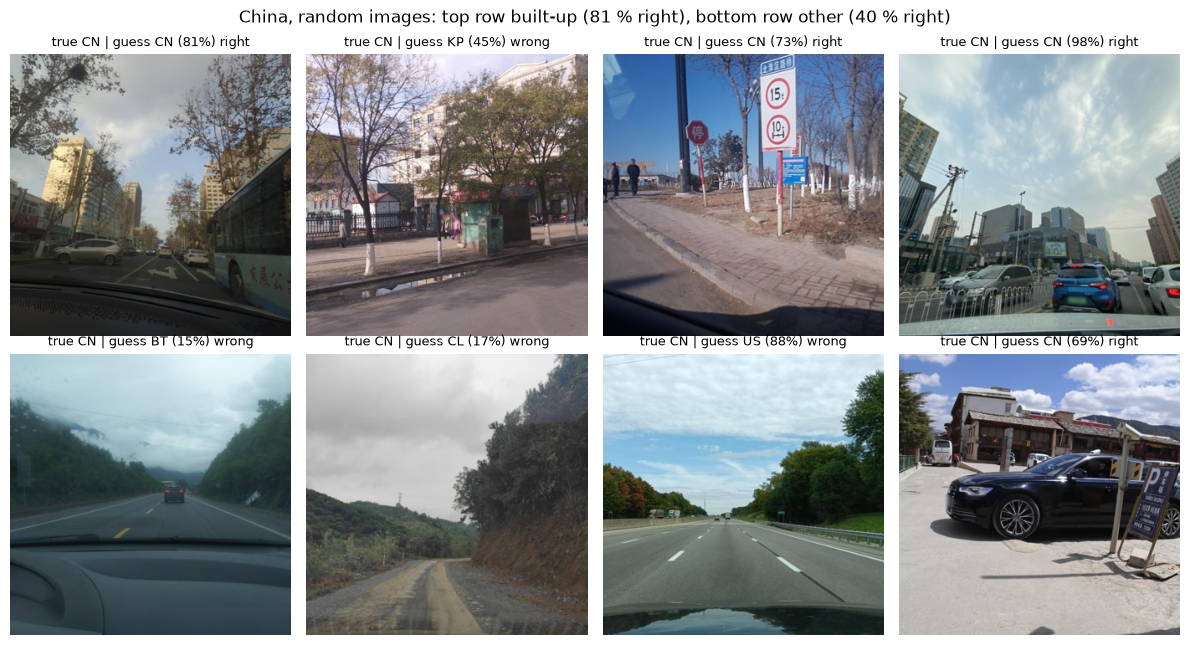

In [36]:
urb = q4.urban_table(env, mapper.table)
urb_cols = {"name": "Country", "size_urban": "Built-up images", "seq_urban": "Built-up sequences",
            "mean_urban": "Accuracy built-up", "mean_rural": "Accuracy other", "diff": "Difference"}
for part in [urb.head(5), urb.tail(5)]:   # worst and best for built-up areas
    display(viz.show_table(part, urb_cols, pct=["mean_urban", "mean_rural"], pts=["diff"],
                           grey=part.seq_urban < q4.MIN_SEQ, index=False))
q4.plot_urban_map(urb).show()
viz.image_grid(dataset, q4.urban_examples(env, "CN"),
               "China, random images: top row built-up (81 % right), bottom row other (40 % right)");

- Numbers behind the Q4 findings: confidence per land cover, how many countries are behind each within-country value, and the change with the paper's prompt

In [37]:
# 1) Confidence vs. accuracy per land cover (> 0: overconfident); within-country: vs. the own country
display(viz.show_table(lc.sort_values("gap", ascending=False),
                       {"n": "Images", "acc": "Accuracy", "conf": "Mean confidence", "gap": "Confidence - accuracy",
                        "w_acc": "Within-country accuracy", "w_conf": "Within-country confidence"},
                       pct=["acc", "conf"], pts=["gap", "w_acc", "w_conf"], grey=lc["low_n"]))

# 2) Within-country values: how many countries are behind them (a country needs >= 20 images in the category)
sea_seq = q4.effect_table(q4.per_sequence(env, "sea_bin"), "sea_bin")
support = pd.concat({"urban, per image": ur, "urban, per sequence": ur_seq, "climate": cl,
                     "sea, per image": sea, "sea, per sequence": sea_seq})
display(viz.show_table(support, {"effect": "Actual - expected", "w_countries": "Countries in check",
                                 "w_acc": "Within-country difference", "w_acc_ci": "95 % CI (+/-)",
                                 "share_better": "Countries above own average"},
                       pct=["share_better"], pts=["effect", "w_acc", "w_acc_ci"]))
us = env[env["country_id"] == "US"]
print(f"US: coast images {us.loc[us.sea_bin == q4.SEA_LABELS[0], 'correct'].mean():.0%} right, "
      f"all US images {us['correct'].mean():.0%}")

# 3) Same tables with the paper's prompt: how much do the numbers move?
if have_old:
    env_old = q4.add_env_columns(decoder.decode(preds_old))
    moved = {}
    for var, label in [("land_cover_name", "land cover"), ("climate_group", "climate"),
                       ("sea_bin", "distance to the sea"), ("urban", "urban")]:
        a = q4.effect_table(env, var).drop(index="no data", errors="ignore")
        b = q4.effect_table(env_old, var).drop(index="no data", errors="ignore")
        moved[label] = {"acc": (a.acc - b.acc).abs().max(), "effect": (a.effect - b.effect).abs().max(),
                        "w_acc": (a.w_acc - b.w_acc).abs().max(), "most": (a.acc - b.acc).abs().idxmax()}
    display(viz.show_table(pd.DataFrame.from_dict(moved, orient="index"),
                           {"acc": "Largest change: accuracy", "most": "... in", "effect": "... actual - expected",
                            "w_acc": "... within-country"}, pts=["acc", "effect", "w_acc"]))

,Images,Accuracy,Mean confidence,Confidence - accuracy,Within-country accuracy,Within-country confidence
bare soil,"10,745",33.9 %,42.2 %,+8.3 pts,-6.5 pts,-1.1 pts
shrubs,"19,622",41.5 %,48.6 %,+7.1 pts,-3.2 pts,-0.5 pts
water bodies,"6,532",46.3 %,49.8 %,+3.5 pts,-3.3 pts,-0.9 pts
grassland,"22,977",46.8 %,49.9 %,+3.2 pts,-2.1 pts,-0.1 pts
tree covered,"53,791",50.2 %,51.4 %,+1.2 pts,-5.2 pts,-2.7 pts
cropland,"71,833",49.5 %,50.3 %,+0.8 pts,+1.8 pts,+0.7 pts
"herbaceous, flooded","2,639",57.8 %,57.1 %,-0.7 pts,+0.4 pts,-0.1 pts
mangroves,191,40.3 %,39.2 %,-1.1 pts,,
artificial surfaces,"10,392",62.3 %,59.1 %,-3.3 pts,+7.2 pts,+4.4 pts
snow and glaciers,91,74.7 %,70.7 %,-4.0 pts,,


US: coast images 47% right, all US images 71%


,Largest change: accuracy,... in,... actual - expected,... within-country
land cover,+7.0 pts,sparse vegetation,+3.0 pts,+1.0 pts
climate,+3.6 pts,A tropical,+3.3 pts,+3.4 pts
distance to the sea,+2.3 pts,0.99-1 (inland),+1.4 pts,+0.4 pts
urban,+1.8 pts,rural / other,+2.2 pts,+0.5 pts


### Q4 findings
- **Climate:** raw accuracy differs a lot (A tropical 35 %, D continental 58 %), but A to D are within 2.5 points of what their country mix predicts. Inside countries the difference is also small (within 3 points). Only E polar is lower (-7.8 points vs. expected, -11.4 within-country), but with few images (1,876) and only 12 countries in the within-country check. So the climate effect is mostly the country mix.
- **Land cover:** the large classes stay within 5 points of their country mix (6 of 11 within 3). "sparse vegetation" looks easy (64 %) only because half of it is Australia. Clear exception: built-up areas (+10.9 points vs. expected, +7.2 within-country). Water bodies (-4.5 / -3.3) and shrubs (-3.4 / -3.2) are worse.
- **Bare soil:** looks very hard (34 %), but its country mix already predicts 36 %. Within-country it is -6.5 points, so smaller countries drop more there. Tree covered shows the same pattern (-1.6 vs. expected, -5.2 within-country).
- **Distance to the sea:** small effects. The coast is worse (-3.7 points vs. expected, also -3.7 with one vote per sequence), far inland is a bit better (+1.6). Mostly big countries: US coast images are 47 % right, the US overall 71 %. With every country counted once the effect is small (-1.5 +/- 2.4 points).
- **Urban vs. rural:** built-up areas are better than the country average in 72 % of 74 countries (+7.2 points). This also holds with one vote per camera sequence (+8.7 points, 52 countries). Very large values for single countries (Libya, Afghanistan) come from only a few sequences.
- **Confidence:** moves with accuracy, but less (built-up: confidence +4.4 points, accuracy +7.2). Bare soil has the largest gap between confidence and accuracy (+8.3 points, overconfident).
- `road_index` has one value per country, so it cannot measure urban vs. rural.
- **Prompt:** numbers use the new shared prompt with the subregion. With the paper's prompt every conclusion above was the same; the effects (actual - expected, within-country) moved by at most 3.5 points, raw accuracies by up to 7 (sparse vegetation 72 % -> 64 %).